QUESTION 5.3 - FINAL LOCKED MODEL EVALUATION
Dataset shape: (144, 14)

Target distribution:
low_reliability
0    105
1     39
Name: count, dtype: int64

FINAL DATA SPLIT
Development samples : 115
Held-out test samples: 29

Held-out test distribution:
low_reliability
0    21
1     8
Name: count, dtype: int64

LOCKED FINAL MODEL
Model        : Logistic Regression
C            : 1
Penalty      : L1
Solver       : liblinear
Class weight : None

No additional hyperparameter tuning is performed.

Final model trained on all 115 development observations.

FINAL HELD-OUT TEST RESULTS


D:\Sekomane\Documents\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
D:\Sekomane\Documents\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,Metric,Final Test Score
0,Accuracy,0.862
1,Precision,0.833
2,Recall,0.625
3,Macro-F1,0.812
4,Weighted-F1,0.855
5,ROC-AUC,0.905
6,PR-AUC,0.834



FINAL CLASSIFICATION REPORT
                           precision    recall  f1-score   support

       Reliable (Class 0)      0.870     0.952     0.909        21
Low Reliability (Class 1)      0.833     0.625     0.714         8

                 accuracy                          0.862        29
                macro avg      0.851     0.789     0.812        29
             weighted avg      0.860     0.862     0.855        29


Confusion Matrix:
[[20  1]
 [ 3  5]]


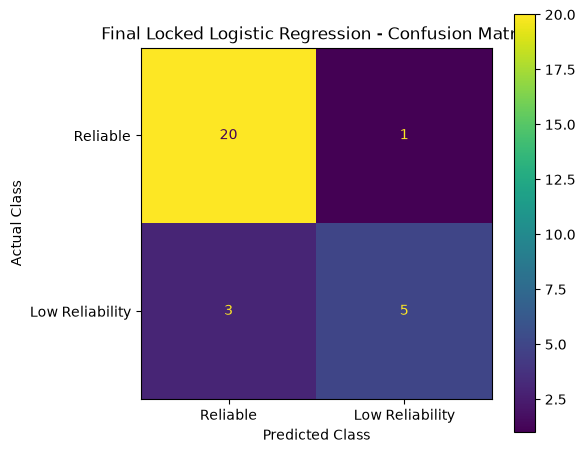

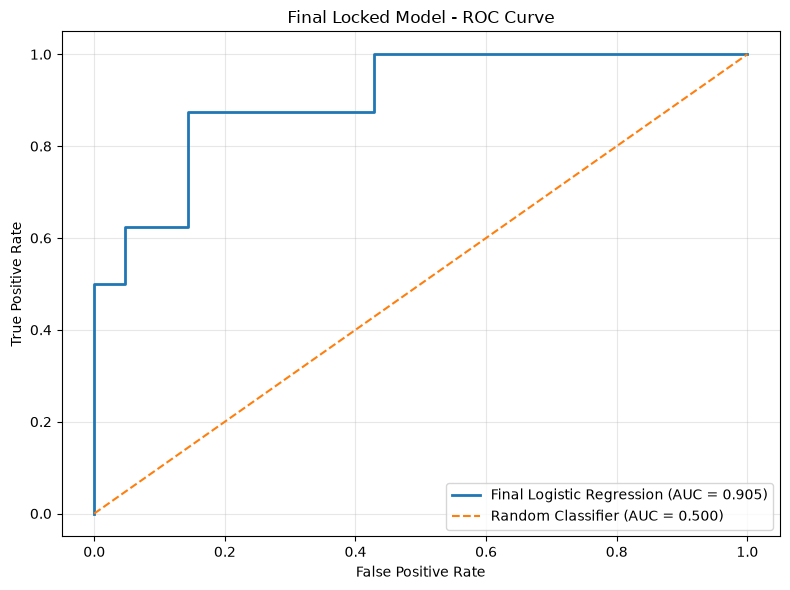


VALIDATION VS FINAL TEST COMPARISON
Optimised CV Macro-F1 : 0.833
Final Test Macro-F1   : 0.812
Difference            : -0.021

Final prediction sample:


,Actual Class,Predicted Class,Probability Low Reliability
0,1,1,0.999900
1,1,0,0.176393
2,0,0,0.118391
3,0,0,0.101900
4,0,0,0.217510
5,0,0,0.139551
6,0,0,0.087245
7,0,0,0.086639
8,0,0,0.063405
9,0,0,0.000002



QUESTION 5.3 COMPLETED SUCCESSFULLY

The final pipeline was locked before this evaluation.
No further model or hyperparameter changes should be made based on these test results.


In [1]:
# =====================================================================
# QUESTION 5.3
# FINAL LOCKED PIPELINE - HELD-OUT TEST EVALUATION
# =====================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

SEED = 42


# =====================================================================
# 1. LOAD DATASET
# =====================================================================

PATH = r"C:\Users\Sekomane\Desktop\Data ScienceTUT\NIWIS_Water Supply Reliability - Population_26-Sep-2026.csv"

df = pd.read_csv(PATH)

print("=" * 80)
print("QUESTION 5.3 - FINAL LOCKED MODEL EVALUATION")
print("=" * 80)

print("Dataset shape:", df.shape)


# =====================================================================
# 2. CLEAN DATA
# =====================================================================

data = df.copy()

# Remove unnamed columns
data = data.loc[
    :,
    ~data.columns.str.contains("^Unnamed")
]

# Standardise column names
data.columns = (
    data.columns
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
)


def clean_number(series):

    return pd.to_numeric(
        series.astype(str)
              .str.replace(" ", "", regex=False)
              .str.replace(",", "", regex=False)
              .str.strip(),
        errors="coerce"
    )


# Convert population/count columns
for col in data.columns:

    if "%" not in col and col != "WSA Name":

        data[col] = clean_number(
            data[col]
        )


# Convert percentage columns
for col in data.columns:

    if "%" in col:

        data[col] = pd.to_numeric(
            data[col]
                .astype(str)
                .str.replace("%", "", regex=False)
                .str.strip(),
            errors="coerce"
        )


# =====================================================================
# 3. CREATE TARGET
# =====================================================================

# Class 0 = Reliable (>= 60%)
# Class 1 = Low Reliability (< 60%)

data["low_reliability"] = (
    data["% Population Reliable Supply"] < 60
).astype(int)


print("\nTarget distribution:")

print(
    data["low_reliability"]
        .value_counts()
        .sort_index()
)


# =====================================================================
# 4. REMOVE LEAKAGE VARIABLES
# =====================================================================

leakage_columns = [

    "Population Reliable Supply",
    "% Population Reliable Supply",

    "Urban Population Reliable Supply",
    "% Urban Population Reliable Supply",

    "Rural Population Reliable Supply",
    "% Rural Population Reliable Supply"
]


y = data["low_reliability"]


X = data.drop(
    columns=[
        "low_reliability",
        "WSA Name"
    ] + leakage_columns,
    errors="ignore"
).copy()


# =====================================================================
# 5. FEATURE ENGINEERING
# =====================================================================

X["population_access_rate"] = (
    X["Population with access to water"]
    / X["Population"]
) * 100


X["urban_access_rate"] = (
    X["Urban Population with access to water"]
    / X["Urban Population"]
) * 100


X["rural_access_rate"] = (
    X["Rural Population with access to water"]
    / X["Rural Population"]
) * 100


X["urban_population_share"] = (
    X["Urban Population"]
    / X["Population"]
) * 100


X["rural_population_share"] = (
    X["Rural Population"]
    / X["Population"]
) * 100


# Handle division by zero
X = X.replace(
    [np.inf, -np.inf],
    np.nan
)


# =====================================================================
# 6. RECREATE THE ORIGINAL HELD-OUT SPLIT
# =====================================================================

# IMPORTANT:
# Same random seed, test size and stratification used throughout
# the project. This recreates the same 29 held-out WSAs.

X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)


print("\n" + "=" * 80)
print("FINAL DATA SPLIT")
print("=" * 80)

print("Development samples :", len(X_dev))
print("Held-out test samples:", len(X_test))

print("\nHeld-out test distribution:")

print(
    y_test.value_counts().sort_index()
)


# =====================================================================
# 7. LOCKED FINAL PIPELINE
# =====================================================================

# These hyperparameters were selected in Q5.1 using development-set
# cross-validation.
#
# NO further tuning is performed in Q5.3.

final_model = Pipeline([

    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),

    (
        "scaler",
        RobustScaler()
    ),

    (
        "classifier",
        LogisticRegression(
            C=1,
            penalty="l1",
            solver="liblinear",
            class_weight=None,
            max_iter=5000,
            random_state=SEED
        )
    )
])


print("\n" + "=" * 80)
print("LOCKED FINAL MODEL")
print("=" * 80)

print("Model        : Logistic Regression")
print("C            : 1")
print("Penalty      : L1")
print("Solver       : liblinear")
print("Class weight : None")

print(
    "\nNo additional hyperparameter tuning is performed."
)


# =====================================================================
# 8. TRAIN FINAL MODEL ON ALL DEVELOPMENT DATA
# =====================================================================

final_model.fit(
    X_dev,
    y_dev
)

print(
    "\nFinal model trained on all 115 development observations."
)


# =====================================================================
# 9. FINAL HELD-OUT TEST PREDICTIONS
# =====================================================================

# This is the final evaluation of the locked pipeline.

y_pred = final_model.predict(
    X_test
)


y_prob = final_model.predict_proba(
    X_test
)[:, 1]


# =====================================================================
# 10. CALCULATE FINAL TEST METRICS
# =====================================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)


precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)


recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)


macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)


weighted_f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)


roc_auc = roc_auc_score(
    y_test,
    y_prob
)


pr_auc = average_precision_score(
    y_test,
    y_prob
)


# =====================================================================
# 11. FINAL TEST RESULTS TABLE
# =====================================================================

final_results = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "Macro-F1",
        "Weighted-F1",
        "ROC-AUC",
        "PR-AUC"
    ],

    "Final Test Score": [
        accuracy,
        precision,
        recall,
        macro_f1,
        weighted_f1,
        roc_auc,
        pr_auc
    ]
})


final_results[
    "Final Test Score"
] = (
    final_results[
        "Final Test Score"
    ].round(3)
)


print("\n" + "=" * 80)
print("FINAL HELD-OUT TEST RESULTS")
print("=" * 80)

display(
    final_results
)


# =====================================================================
# 12. CLASSIFICATION REPORT
# =====================================================================

print("\n" + "=" * 80)
print("FINAL CLASSIFICATION REPORT")
print("=" * 80)


print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Reliable (Class 0)",
            "Low Reliability (Class 1)"
        ],
        digits=3,
        zero_division=0
    )
)


# =====================================================================
# 13. CONFUSION MATRIX
# =====================================================================

cm = confusion_matrix(
    y_test,
    y_pred
)


print(
    "\nConfusion Matrix:"
)

print(cm)


fig, ax = plt.subplots(
    figsize=(6, 5)
)


ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Reliable",
        "Low Reliability"
    ]
).plot(
    ax=ax,
    values_format="d"
)


ax.set_title(
    "Final Locked Logistic Regression - Confusion Matrix"
)

ax.set_xlabel(
    "Predicted Class"
)

ax.set_ylabel(
    "Actual Class"
)

plt.tight_layout()

plt.show()


# =====================================================================
# 14. FINAL ROC CURVE
# =====================================================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)


plt.figure(
    figsize=(8, 6)
)


plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Final Logistic Regression (AUC = {roc_auc:.3f})"
)


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier (AUC = 0.500)"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)


plt.title(
    "Final Locked Model - ROC Curve"
)


plt.legend(
    loc="lower right"
)


plt.grid(
    alpha=0.3
)


plt.tight_layout()

plt.show()


# =====================================================================
# 15. VALIDATION VS FINAL TEST COMPARISON
# =====================================================================

# Optimised CV result obtained during Q5.1/Q5.2.
# This is NOT used to change the model.
# It is displayed only for comparison.

optimized_cv_macro_f1 = 0.833


difference = (
    macro_f1
    - optimized_cv_macro_f1
)


print("\n" + "=" * 80)
print("VALIDATION VS FINAL TEST COMPARISON")
print("=" * 80)


print(
    "Optimised CV Macro-F1 :",
    optimized_cv_macro_f1
)


print(
    "Final Test Macro-F1   :",
    round(
        macro_f1,
        3
    )
)


print(
    "Difference            :",
    round(
        difference,
        3
    )
)


# =====================================================================
# 16. SAVE FINAL TEST PREDICTIONS
# =====================================================================

# Useful as reproducibility/evidence for the project.

prediction_output = pd.DataFrame({

    "Actual Class":
        y_test.values,

    "Predicted Class":
        y_pred,

    "Probability Low Reliability":
        y_prob
})


print("\nFinal prediction sample:")

display(
    prediction_output.head(10)
)


# =====================================================================
# 17. COMPLETION MESSAGE
# =====================================================================

print("\n" + "=" * 80)

print(
    "QUESTION 5.3 COMPLETED SUCCESSFULLY"
)

print("=" * 80)


print(
    "\nThe final pipeline was locked before this evaluation."
)

print(
    "No further model or hyperparameter changes should be made "
    "based on these test results."
)